# Chapitre 3 - Exercices 3.7 à 3.12

Ce notebook traite les six derniers exercices du chapitre 3, consacrés à la similarité,
aux juges IA et au classement comparatif :

- **3.7** : calculer BLEU à la main (précisions écrêtées, pénalité de brièveté) ;
- **3.8** : métriques lexicales contre sémantiques face à des jugements humains (mini-lab) ;
- **3.9** : mesurer et corriger le biais de position d'un juge IA (mini-lab) ;
- **3.10** : budget d'un juge IA en production et taille de l'échantillon contrôlé ;
- **3.11** : Elo à la main, sensibilité à l'ordre, et Elo vu comme une descente de gradient ;
- **3.12** : la table 3-6 du livre, les chiffres de LMSYS et l'appariement adaptatif.

In [1]:
import math
from collections import Counter
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm, spearmanr

from aie import ch03_evaluation as ev
from aie import llm
from aie.diagrams import Diagram
from aie.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                          annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
rng = np.random.default_rng(0)
llm.seed_everything(0)
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 70)

## Exercice 3.7 : BLEU à la main

**Énoncé.** Candidat : « the cat sat on the mat today ». Références :
R1 = « the cat sat on the mat » et R2 = « a cat was sitting on the mat today ».

1. Calculer les précisions écrêtées $p_1$ à $p_4$.
2. Calculer la pénalité de brièveté et le score BLEU (sans lissage).
3. Que deviendrait BLEU pour le candidat « the cat » ? Pour « the the the the the the
   the » ? Pourquoi utilise-t-on une moyenne **géométrique** des $p_n$ ?

**Rappels.** $p_n$ = (nombre de n-grammes du candidat, chacun compté au plus autant de
fois que dans la référence qui en contient le plus) / (nombre de n-grammes du candidat) ;
$\mathrm{BP} = \min(1, e^{1 - r/c})$ avec $r$ la longueur de la référence la plus proche
de $c$ ; $\mathrm{BLEU} = \mathrm{BP}\exp(\frac14\sum_n \log p_n)$ (section *Lexical
similarity*, cours 2 section 6).

**Solution.** Le candidat a $c = 7$ mots.

- **Unigrammes** (7) : the (x2), cat, sat, on, mat, today. « the » apparaît 2 fois dans
  R1 : écrêté à 2 ; cat, sat, on, mat sont dans R1 ; today est dans R2. Tous comptent :
  $p_1 = 7/7 = 1$.
- **Bigrammes** (6) : the cat, cat sat, sat on, on the, the mat, mat today. Les cinq
  premiers sont dans R1, « mat today » dans R2 : $p_2 = 6/6 = 1$.
- **Trigrammes** (5) : the cat sat, cat sat on, sat on the, on the mat (R1), the mat
  today (R2) : $p_3 = 5/5 = 1$.
- **4-grammes** (4) : the cat sat on, cat sat on the, sat on the mat (R1) ; « on the mat
  today » est dans R2 : $p_4 = 4/4 = 1$.

Toutes les précisions valent 1, alors qu'aucune référence n'est identique au candidat :
BLEU récompense des morceaux empruntés à des références **différentes**. Longueurs des
références : 6 et 8, toutes deux à distance 1 de $c = 7$ ; on prend la plus courte (6,
convention usuelle) : $c > r$, donc $\mathrm{BP} = 1$ et $\mathrm{BLEU} = 1$.

*3.* « the cat » : $p_1 = p_2 = 1$, mais aucun trigramme ni 4-gramme : sans lissage,
$p_3 = p_4$ indéfinis (0/0, comptés comme nuls) et BLEU $= 0$ ; même avec $p_n = 1$, la
pénalité vaudrait $e^{1 - 6/2} = e^{-2} \approx 0{,}14$. « the » x7 : $p_1 = 2/7$
(écrêtage), aucun bigramme valide : BLEU $= 0$. La moyenne géométrique fait qu'un seul
ordre de n-grammes nul annule le score : un candidat doit être bon à **tous** les ordres,
ce qui pénalise les sacs de mots corrects mais mal ordonnés. $\blacksquare$

In [2]:
cand = "the cat sat on the mat today"
refs = ["the cat sat on the mat", "a cat was sitting on the mat today"]
rows = []
for n in range(1, 5):
    cn = ev.ngrams(ev.words(cand), n)
    mx = Counter()
    for r in refs:
        mx |= ev.ngrams(ev.words(r), n)
    rows.append(dict(n=n, ngrammes=sum(cn.values()), ecretes=sum(min(v, mx[g]) for g, v in cn.items())))
T = pd.DataFrame(rows)
T["p_n"] = T.ecretes / T.ngrammes
print(T.to_string(index=False))
print("BLEU (module, sans lissage) :", ev.bleu(cand, refs, smooth=False))
print("« the cat » :", ev.bleu("the cat", refs, smooth=False), "| avec lissage :", round(ev.bleu("the cat", refs), 4))
print("« the » x7 :", ev.bleu("the the the the the the the", refs, smooth=False))

 n  ngrammes  ecretes  p_n
 1         7        7  1.0
 2         6        6  1.0
 3         5        5  1.0
 4         4        4  1.0
BLEU (module, sans lissage) : 1.0
« the cat » : 0.0 | avec lissage : 0.0957
« the » x7 : 0.0


**Vérification graphique** : la pénalité de brièveté en fonction du rapport $c/r$.

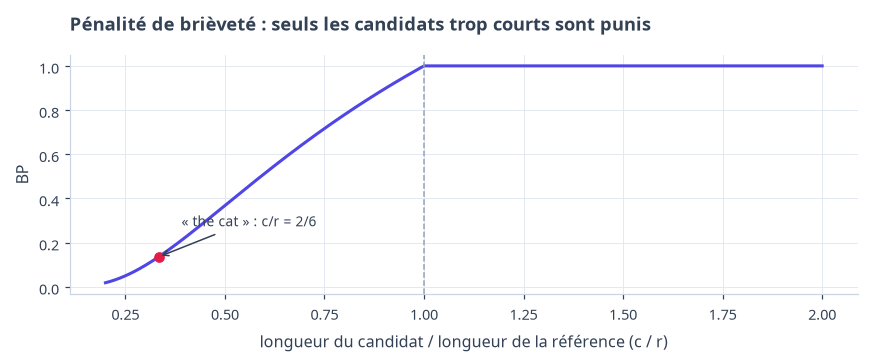

In [3]:
ratio = np.linspace(0.2, 2, 300)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(ratio, np.where(ratio > 1, 1, np.exp(1 - 1 / ratio)), color=INDIGO)
ax.axvline(1, color=GRAY, ls="--", lw=1)
ax.scatter([2 / 6], [math.exp(1 - 3)], color=ROSE, zorder=3)
ax.annotate("« the cat » : c/r = 2/6", (2 / 6, math.exp(-2)), (15, 20), textcoords="offset points",
            arrowprops=dict(arrowstyle="->", color=SLATE), fontsize=9)
ax.set_xlabel("longueur du candidat / longueur de la référence (c / r)"); ax.set_ylabel("BP")
ax.set_title("Pénalité de brièveté : seuls les candidats trop courts sont punis")
plt.tight_layout(); plt.show()

> **À retenir.** BLEU = moyenne géométrique des précisions écrêtées des 1- à 4-grammes,
> multipliée par une pénalité de brièveté. Il peut donner 1 à un candidat qui recoud des
> morceaux de références différentes, et 0 à une phrase courte correcte sans lissage.

## Exercice 3.8 : Métriques lexicales contre sémantiques face au jugement humain

**Énoncé.** On dispose de 14 paires (référence, réponse) annotées par un humain avec une
note d'équivalence de sens entre 0 (sens différent) et 1 (même sens).

1. Calculer pour chaque paire ROUGE-L, la similarité d'édition, BLEU lissé et la
   similarité cosinus (all-MiniLM-L6-v2).
2. Mesurer la corrélation de Spearman de chaque métrique avec le jugement humain.
3. Identifier, pour chaque métrique, la paire sur laquelle elle se trompe le plus, et
   expliquer pourquoi.

**Rappels.** Similarité lexicale (forme) contre sémantique (embeddings et cosinus)
(sections *Lexical similarity* et *Semantic similarity*, cours 2 section 6 et cours 3
section 1).

In [4]:
paires = [
    ("The meeting is postponed to Friday.", "The meeting has been moved to Friday.", 1.0),
    ("The meeting is postponed to Friday.", "The meeting is postponed to Monday.", 0.1),
    ("The meeting is postponed to Friday.", "Friday's the new date for our meeting.", 1.0),
    ("Turn off the oven after 20 minutes.", "Switch the oven off once 20 minutes have passed.", 1.0),
    ("Turn off the oven after 20 minutes.", "Do not turn off the oven after 20 minutes.", 0.0),
    ("The medication must be taken with food.", "Take the medicine during a meal.", 0.9),
    ("The medication must be taken with food.", "The medication must be taken without food.", 0.0),
    ("Sales grew by 10% this year.", "This year, revenue from sales rose ten percent.", 0.9),
    ("Sales grew by 10% this year.", "Sales fell by 10% this year.", 0.0),
    ("The bridge was closed for repairs.", "Repairs forced the bridge to close.", 1.0),
    ("The bridge was closed for repairs.", "The bridge was opened after repairs.", 0.2),
    ("He forgot his umbrella at home.", "He left his umbrella at home by mistake.", 0.9),
    ("He forgot his umbrella at home.", "She bought a new umbrella yesterday.", 0.1),
    ("The password must contain a digit.", "Passwords need at least one number.", 1.0),
]
refs_ = [a for a, _, _ in paires]
cands = [b for _, b, _ in paires]
Er, Ec = llm.embed(refs_), llm.embed(cands)
M = pd.DataFrame(dict(reference=refs_, reponse=cands, humain=[h for *_, h in paires]))
M["rouge_l"] = [ev.rouge_l(c, r)["f1"] for r, c in zip(refs_, cands)]
M["edition"] = [ev.edit_similarity(c.lower(), r.lower()) for r, c in zip(refs_, cands)]
M["bleu"] = [ev.bleu(c, r) for r, c in zip(refs_, cands)]
M["cosinus"] = (Er * Ec).sum(1)
metriques = ["rouge_l", "edition", "bleu", "cosinus"]
corr = pd.Series({m: spearmanr(M[m], M.humain).statistic for m in metriques}, name="Spearman avec l'humain")
corr.to_frame().T

,rouge_l,edition,bleu,cosinus
Spearman avec l'humain,-0.6431,-0.7609,-0.6564,-0.2271


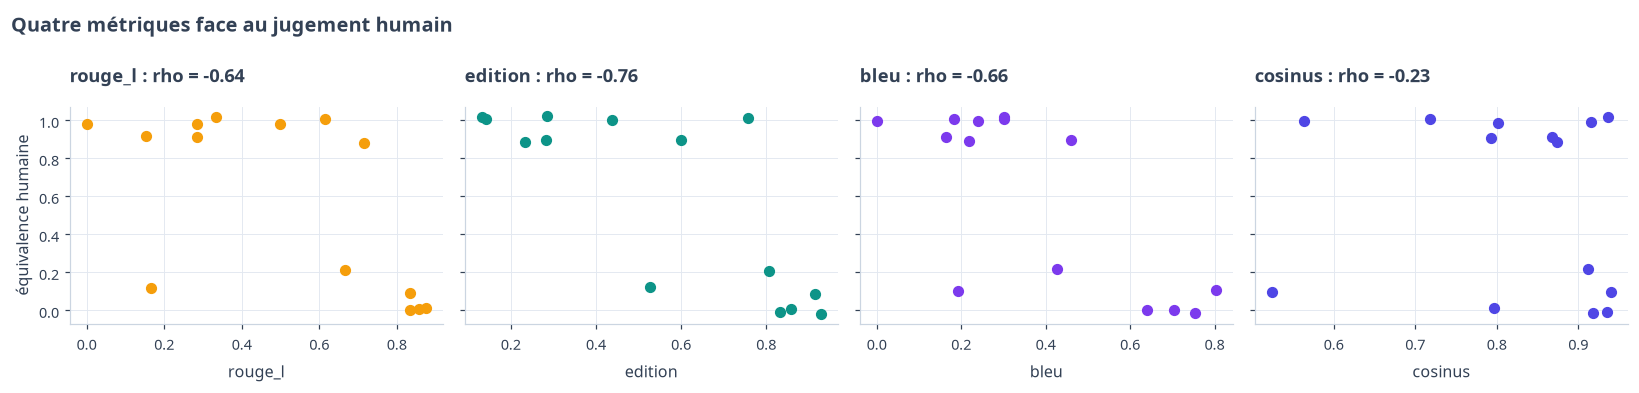

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for ax, m, c in zip(axes, metriques, [AMBER, TEAL, VIOLET, INDIGO]):
    ax.scatter(M[m], M.humain + rng.uniform(-0.02, 0.02, len(M)), color=c, s=40, zorder=3)
    ax.set_title(f"{m} : rho = {corr[m]:.2f}"); ax.set_xlabel(m)
axes[0].set_ylabel("équivalence humaine")
finish(fig, "Quatre métriques face au jugement humain")
plt.show()

**Solution.** Pour trouver l'erreur la plus grave de chaque métrique, on normalise ses
scores en rangs (entre 0 et 1) et l'on cherche la paire où le rang s'écarte le plus de
la note humaine.

In [6]:
pires = {}
for m in metriques:
    r = M[m].rank(pct=True)
    i = (r - M.humain).abs().idxmax()
    pires[m] = dict(reference=M.reference[i], reponse=M.reponse[i], humain=M.humain[i], score=round(M[m][i], 3))
pd.DataFrame(pires).T

,reference,reponse,humain,score
rouge_l,Turn off the oven after 20 minutes.,Do not turn off the oven after 20 minutes.,0.0,0.875
edition,The medication must be taken with food.,The medication must be taken without food.,0.0,0.929
bleu,Turn off the oven after 20 minutes.,Do not turn off the oven after 20 minutes.,0.0,0.755
cosinus,The meeting is postponed to Friday.,The meeting is postponed to Monday.,0.1,0.94


Sur ce jeu volontairement piégé, **toutes** les corrélations sont négatives : les
métriques notent mieux les quasi-copies au sens inversé (« postponed to Monday »,
« without food », « fell » au lieu de « grew »), que l'humain juge fausses, que les
paraphrases, que l'humain juge équivalentes. Les métriques lexicales sont les plus
trompées ; le cosinus l'est moins (il reconnaît mieux les paraphrases) mais note encore
très haut les négations et les inversions (même sujet, même vocabulaire). Sur un jeu
« naturel », sans pièges, les corrélations seraient positives : c'est précisément la
composition du jeu de test qui révèle les angles morts. Aucune métrique de similarité ne remplace une
vérification du sens pour les détails critiques (dates, négations, chiffres) : c'est
l'une des motivations des juges IA.

> **À retenir.** Les métriques lexicales mesurent la forme, les embeddings le sujet ; ni
> l'une ni l'autre ne capte de façon fiable la négation ou les erreurs factuelles. Mesurer
> la corrélation d'une métrique avec des jugements humains est le seul moyen de savoir
> ce qu'elle vaut sur sa tâche.

## Exercice 3.9 : Mesurer et corriger le biais de position d'un juge

**Énoncé.** On utilise Qwen2.5-1.5B-Instruct comme juge par paires. Pour 8 questions, on
dispose de **deux bonnes réponses** de formulations différentes : un juge impartial
devrait être indifférent (50 %), en moyenne, et surtout **cohérent** quand on permute.

1. Mesurer $P(\text{A})$ quand la réponse 1 est en position A, puis en position B. En
   déduire le taux de préférence pour la position A et le taux de verdicts incohérents.
2. Proposer un score corrigé et vérifier qu'il est invariant par permutation.
3. Combien d'appels au juge la correction coûte-t-elle ?

**Rappels.** Biais de première position des juges IA, parade par répétition dans les
deux ordres (section *Biases of AI as a judge*, cours 3 section 5).

In [7]:
duels = [
    ("What is the capital of Australia?", "Canberra.", "The capital city of Australia is Canberra."),
    ("How many legs does a spider have?", "Eight.", "Spiders have 8 legs."),
    ("What is 12 times 11?", "132", "12 multiplied by 11 equals 132."),
    ("Who wrote 'Pride and Prejudice'?", "Jane Austen.", "It was written by the English novelist Jane Austen."),
    ("What gas do plants absorb for photosynthesis?", "Carbon dioxide (CO2).", "They take in CO2 from the air."),
    ("What is the largest planet of the Solar System?", "Jupiter is the largest.", "Jupiter."),
    ("At what temperature does water boil at sea level, in Celsius?", "100 °C.", "It boils at 100 degrees Celsius."),
    ("What is the chemical symbol of gold?", "Au.", "The symbol for gold is Au, from the Latin aurum."),
]
rows = []
for q, r1, r2 in duels:
    pA_12 = ev.judge_pairwise(q, r1, r2, llm.MEDIUM)   # P(préfère A) avec r1 en A
    pA_21 = ev.judge_pairwise(q, r2, r1, llm.MEDIUM)   # P(préfère A) avec r2 en A
    rows.append(dict(question=q[:38], P_A_r1_en_A=pA_12, P_A_r2_en_A=pA_21))
PB = pd.DataFrame(rows)
PB["P_r1_ordre1"] = PB.P_A_r1_en_A
PB["P_r1_ordre2"] = 1 - PB.P_A_r2_en_A
PB["P_r1_corrige"] = (PB.P_r1_ordre1 + PB.P_r1_ordre2) / 2
PB["incoherent"] = (PB.P_r1_ordre1 > 0.5) != (PB.P_r1_ordre2 > 0.5)
pref_A = np.mean(np.r_[PB.P_A_r1_en_A, PB.P_A_r2_en_A])
print(f"Probabilité moyenne de choisir la position A : {pref_A:.2f} (0,5 = impartial) ; "
      f"verdicts incohérents : {PB.incoherent.mean():.0%}")
PB[["question", "P_r1_ordre1", "P_r1_ordre2", "P_r1_corrige", "incoherent"]]

Probabilité moyenne de choisir la position A : 0.93 (0,5 = impartial) ; verdicts incohérents : 88%


,question,P_r1_ordre1,P_r1_ordre2,P_r1_corrige,incoherent
0,What is the capital of Australia?,0.9933,0.0017,0.4975,True
1,How many legs does a spider have?,0.9941,0.0141,0.5041,True
2,What is 12 times 11?,0.9959,0.0004,0.4982,True
3,Who wrote 'Pride and Prejudice'?,0.9978,0.0041,0.5009,True
4,What gas do plants absorb for photosyn,0.9959,0.8176,0.9068,False
5,What is the largest planet of the Sola,0.9933,0.0052,0.4993,True
6,At what temperature does water boil at,0.9959,0.1192,0.5576,True
7,What is the chemical symbol of gold?,0.8176,0.0022,0.4099,True


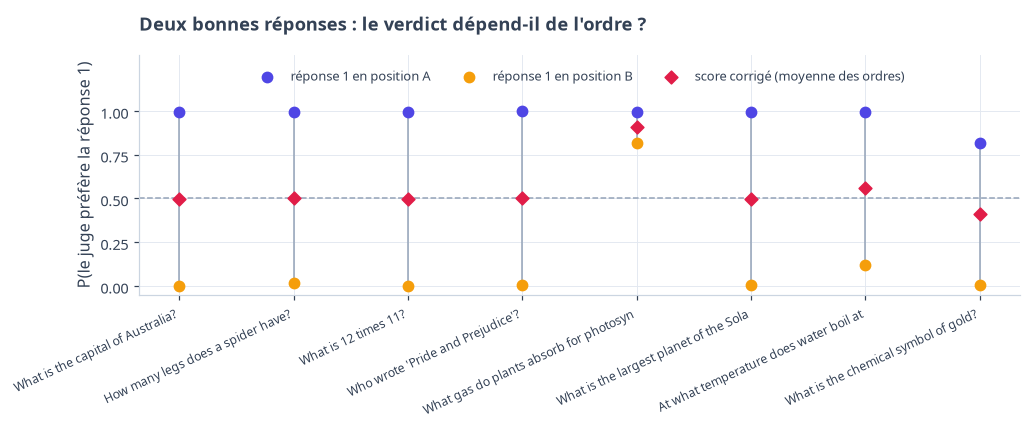

In [8]:
fig, ax = plt.subplots(figsize=(9.5, 4))
x = np.arange(len(PB))
ax.scatter(x, PB.P_r1_ordre1, color=INDIGO, s=45, label="réponse 1 en position A", zorder=3)
ax.scatter(x, PB.P_r1_ordre2, color=AMBER, s=45, label="réponse 1 en position B", zorder=3)
ax.vlines(x, PB.P_r1_ordre1, PB.P_r1_ordre2, color=GRAY, lw=1)
ax.scatter(x, PB.P_r1_corrige, marker="D", color=ROSE, s=35, label="score corrigé (moyenne des ordres)", zorder=4)
ax.axhline(0.5, color=GRAY, ls="--", lw=1)
ax.set_xticks(x); ax.set_xticklabels(PB.question, rotation=25, ha="right", fontsize=8)
ax.set_ylabel("P(le juge préfère la réponse 1)"); ax.set_ylim(-0.05, 1.32); ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
ax.set_title("Deux bonnes réponses : le verdict dépend-il de l'ordre ?")
ax.legend(fontsize=8.5, loc="upper center", ncol=3)
plt.tight_layout(); plt.show()

**Solution.**

*1.* Le résultat est frappant : le juge de 1,5 B, cohérent sur les duels faciles du
cours 3 (bonne contre mauvaise réponse), choisit presque toujours la position A dès que
les deux réponses se valent, et la plupart de ses verdicts s'inversent quand on permute.
Entre deux réponses également bonnes, un juge biaisé vers la première position
donne $P(\text{A}) > 0{,}5$ quel que soit le contenu : le segment gris relie les deux
verdicts sur le même duel ; plus il est long, plus l'ordre pèse. Les valeurs mesurées
ci-dessus quantifient ce biais pour notre juge (préférence moyenne pour A et part de
verdicts qui s'inversent avec l'ordre). Les duels où le juge préfère nettement une
réponse dans les deux ordres traduisent une préférence de **contenu** (souvent la
réponse la plus longue ou la plus explicite, cf. biais de verbosité).

*2.* Score corrigé :
$s(r_1, r_2) = \tfrac12\big[P(\text{A} \mid r_1, r_2) + 1 - P(\text{A} \mid r_2, r_1)\big]$.
Permuter $r_1$ et $r_2$ donne
$\tfrac12[P(\text{A}\mid r_2, r_1) + 1 - P(\text{A}\mid r_1, r_2)] = 1 - s(r_1, r_2)$ :
le score de $r_2$ est bien le complément de celui de $r_1$, **quel que soit** le biais
de position s'il est additif. On peut aussi n'accepter que les verdicts cohérents dans
les deux ordres et déclarer une égalité sinon.

*3.* La correction double le nombre d'appels (2 au lieu de 1 par duel) et donc le coût
du juge. $\blacksquare$

In [9]:
verif = [abs(ev.judge_pairwise(q, r2, r1, llm.MEDIUM) - ev.judge_pairwise(q, r2, r1, llm.MEDIUM)) for q, r1, r2 in duels[:2]]
s12 = PB.P_r1_corrige.values
s21 = 0.5 * (PB.P_A_r2_en_A + 1 - PB.P_A_r1_en_A).values
print("s(r1, r2) + s(r2, r1) =", np.round(s12 + s21, 6), "| déterminisme du juge :", verif)

s(r1, r2) + s(r2, r1) = [1. 1. 1. 1. 1. 1. 1. 1.] | déterminisme du juge : [0.0, 0.0]


> **À retenir.** Mesurer le biais de position demande des duels « à égalité » présentés
> dans les deux ordres. Moyenner les deux ordres rend le score invariant par permutation,
> au prix d'un doublement des appels.

## Exercice 3.10 : Budget d'un juge IA en production

**Énoncé.** Une application reçoit 2 millions de requêtes par mois (500 tokens en entrée,
300 en sortie). Le générateur coûte 0,5 \$ / M tokens en entrée et 1,5 \$ en sortie. On
veut suivre trois critères (justesse, fidélité au contexte, toxicité). Prix **fictifs**
des juges : (J1) le même modèle que le générateur ; (J2) un petit juge spécialisé 10 fois
moins cher ; (J3) un grand modèle à 5 \$ / 15 \$, appliqué à un échantillon. La consigne
de chaque juge fait 400 tokens ; il répond en 10 tokens.

1. Calculer le coût mensuel de la génération et de chaque option si l'on juge 100 % du
   trafic.
2. Avec J3, quelle fraction du trafic peut-on juger pour un surcoût de 20 % ?
3. Combien de réponses faut-il juger pour estimer un taux d'échec de l'ordre de 5 % à
   ±1 point (95 %) ? Et pour détecter un passage de 5 % à 6 % d'un mois sur l'autre
   (test bilatéral à 5 %, puissance 80 %) ?

**Rappels.** Coût d'un juge = tokens relus (entrée + sortie de l'application + consigne)
et produits, par critère ; échantillonnage (« spot-checking »)
(section *Increased costs and latency*, cours 3 section 8). Taille d'échantillon pour une
proportion : $n = z^2 p(1-p)/\varepsilon^2$ ; pour comparer deux proportions :
$n = \big(z_{1-\alpha/2}\sqrt{2\bar p(1-\bar p)} + z_{1-\beta}\sqrt{p_1(1-p_1) + p_2(1-p_2)}\big)^2/(p_1-p_2)^2$
par groupe.

**Solution.**

*1.* Génération : $2\cdot10^6 \times (500 \times 0{,}5 + 300\times1{,}5)/10^6 = 2 \times 700 = 1\,400$ \$.
Un appel de juge relit $500 + 300 + 400 = 1\,200$ tokens et en produit 10. J1 :
$2\cdot10^6 \times 3 \times (1\,200\times0{,}5 + 10\times1{,}5)/10^6 = 6 \times 615 = 3\,690$ \$
(+264 %) ; J2 : 369 \$ ; J3 : $6\times(1\,200\times5 + 10\times15) = 36\,900$ \$.

*2.* Il faut $36\,900\,f = 0{,}2 \times 1\,400 = 280$ \$, soit $f \approx 0{,}76\,\%$,
environ 15 000 réponses par mois.

*3.* $n = 1{,}96^2 \times 0{,}05\times0{,}95/0{,}01^2 \approx 1\,825$ réponses. Pour
détecter 5 % contre 6 %, la formule donne environ 8 000 réponses **par mois** : petit
devant 2 millions, mais plus de quatre fois plus que pour la simple estimation. $\blacksquare$

In [10]:
options = {"J1 (même modèle)": (0.5, 1.5), "J2 (petit juge)": (0.05, 0.15), "J3 (grand modèle)": (5.0, 15.0)}
base = dict(n_requests=2_000_000, gen_in=500, gen_out=300, judge_out=10, judge_overhead=400, n_criteria=3)
rows = {}
for nom, (pi, po) in options.items():
    c_gen = ev.judge_cost(**base, price_in=0.5, price_out=1.5, sample_rate=0)["generation"]
    c = ev.judge_cost(**base, price_in=pi, price_out=po, sample_rate=1.0)
    rows[nom] = dict(generation=c_gen, juge_100pct=c["juge"], surcout=c["juge"] / c_gen)
CB = pd.DataFrame(rows).T
f20 = 0.2 * CB.generation.iloc[0] / CB.loc["J3 (grand modèle)", "juge_100pct"]
print(f"Fraction jugeable par J3 pour +20 % : {f20:.2%} soit {f20 * 2e6:,.0f} réponses / mois".replace(",", " "))
p1, p2 = 0.05, 0.06
pb_ = (p1 + p2) / 2
n_cmp = (norm.ppf(0.975) * math.sqrt(2 * pb_ * (1 - pb_)) + norm.ppf(0.8) * math.sqrt(p1 * (1 - p1) + p2 * (1 - p2))) ** 2 / (p1 - p2) ** 2
print(f"Estimation à ±1 pt : {ev.spot_check_sample_size(0.05, 0.01)} réponses ; détection 5 % -> 6 % : {math.ceil(n_cmp)} par mois")
CB

Fraction jugeable par J3 pour +20 % : 0.76% soit 15 176 réponses / mois
Estimation à ±1 pt : 1825 réponses ; détection 5 % -> 6 % : 8158 par mois


,generation,juge_100pct,surcout
J1 (même modèle),1400.0,3690.0,2.6357
J2 (petit juge),1400.0,369.0,0.2636
J3 (grand modèle),1400.0,36900.0,26.3571


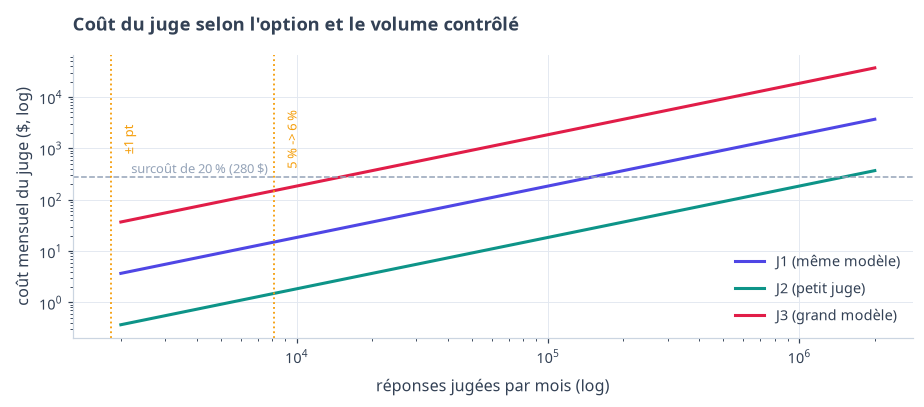

In [11]:
fracs = np.logspace(-3, 0, 100)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for (nom, (pi, po)), c in zip(options.items(), [INDIGO, TEAL, ROSE]):
    cout = [ev.judge_cost(**base, price_in=pi, price_out=po, sample_rate=f)["juge"] for f in fracs]
    ax.plot(fracs * 2e6, cout, color=c, label=nom)
ax.axhline(280, color=GRAY, ls="--", lw=1); ax.text(2.2e3, 330, "surcoût de 20 % (280 $)", fontsize=8.5, color=GRAY)
for n_, lab in [(1825, "±1 pt"), (math.ceil(n_cmp), "5 % -> 6 %")]:
    ax.axvline(n_, color=AMBER, ls=":", lw=1.2); ax.text(n_ * 1.08, 1500, lab, fontsize=8.5, color=AMBER, rotation=90, va="center")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("réponses jugées par mois (log)"); ax.set_ylabel("coût mensuel du juge ($, log)")
ax.set_title("Coût du juge selon l'option et le volume contrôlé")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

Le graphique résume la décision : un grand juge reste abordable s'il ne contrôle qu'un
échantillon de quelques milliers de réponses, suffisant pour suivre des taux d'échec de
quelques pour cent. Juger 100 % du trafic n'est justifié que si le juge sert de
**garde-fou** (bloquer les mauvaises réponses), auquel cas un petit juge spécialisé est
le seul choix économique, et sa latence compte aussi.

> **À retenir.** Le coût d'un juge se calcule comme celui de l'application (tokens relus
> et produits, par critère). L'échantillonnage le rend négligeable pour le suivi ; la
> taille de l'échantillon se déduit de la précision voulue.

## Exercice 3.11 : Elo à la main, sensibilité à l'ordre, Elo = gradient stochastique

**Énoncé.** Trois modèles A, B, C commencent à 1 000 points, $K = 32$.

1. Calculer les scores après la séquence : A bat B, B bat C, C bat A, A bat B.
2. Recalculer avec la séquence inverse (A bat B, C bat A, B bat C, A bat B). Commenter.
3. Montrer que la somme des scores est conservée.
4. Vérifier numériquement que la mise à jour d'Elo est un pas de gradient sur la
   log-vraisemblance du match, avec un pas $\eta = 400K/\ln 10$.

**Rappels.** $E_A = 1/(1 + 10^{(R_B - R_A)/400})$, $R_A \leftarrow R_A + K(S - E_A)$
(section *Ranking Models with Comparative Evaluation*, cours 4 sections 2 et 3).

**Solution.**

*1.* Match 1 : $E_A = 0{,}5$, A gagne : A $= 1\,016$, B $= 984$. Match 2 (B bat C) :
$E_B = 1/(1 + 10^{16/400}) = 0{,}4770$, B gagne $32\times0{,}5230 = 16{,}74$ :
B $= 1\,000{,}74$, C $= 983{,}26$. Match 3 (C bat A) : $E_C = 1/(1 + 10^{32{,}74/400}) = 0{,}4530$,
C gagne $17{,}50$ : C $= 1\,000{,}77$, A $= 998{,}50$. Match 4 (A bat B) :
$E_A = 1/(1+10^{2{,}24/400}) = 0{,}4968$, A gagne $16{,}10$ : A $= 1\,014{,}60$,
B $= 984{,}63$, C $= 1\,000{,}77$.

*2.* Le tableau ci-dessous donne le résultat de la seconde séquence : **mêmes matchs,
scores différents**, parce que l'espérance $E$ de chaque match dépend des scores du
moment.

*3.* Chaque match ajoute $K(S - E_A)$ à A et retire la même quantité à B (car
$E_B = 1 - E_A$ et $S_B = 1 - S_A$) : la somme reste $3\,000$.

*4.* $\partial\ell/\partial R_A = (S - E_A)\ln 10/400$, donc
$K(S - E_A) = \eta\,\partial\ell/\partial R_A$ avec $\eta = 400K/\ln 10 \approx 5\,559$
pour $K = 32$. $\blacksquare$

In [12]:
def elo_seq(seq, K=32):
    r = {"A": 1000.0, "B": 1000.0, "C": 1000.0}
    hist = []
    for g, p in seq:
        r[g], r[p] = ev.elo_update(r[g], r[p], 1.0, k=K)
        hist.append(dict(match=f"{g} bat {p}", **{k: round(v, 2) for k, v in r.items()}, somme=round(sum(r.values()), 6)))
    return pd.DataFrame(hist)


s1 = elo_seq([("A", "B"), ("B", "C"), ("C", "A"), ("A", "B")])
s2 = elo_seq([("A", "B"), ("C", "A"), ("B", "C"), ("A", "B")])
display(s1); display(s2)

,match,A,B,C,somme
0,A bat B,1016.0,984.00,1000.00,3000.0
1,B bat C,1016.0,1000.74,983.26,3000.0
2,C bat A,998.5,1000.74,1000.77,3000.0
3,A bat B,1014.6,984.63,1000.77,3000.0


,match,A,B,C,somme
0,A bat B,1016.00,984.0,1000.00,3000.0
1,C bat A,999.26,984.0,1016.74,3000.0
2,B bat C,999.26,1001.5,999.23,3000.0
3,A bat B,1015.37,985.4,999.23,3000.0


In [13]:
Ra, Rb, S, K = 1030.0, 980.0, 0.0, 32
loglik = lambda ra: S * math.log(ev.elo_expected(ra, Rb)) + (1 - S) * math.log(1 - ev.elo_expected(ra, Rb))
grad = (loglik(Ra + 1e-4) - loglik(Ra - 1e-4)) / 2e-4
pas_elo = ev.elo_update(Ra, Rb, S, k=K)[0] - Ra
print(f"pas Elo = {pas_elo:.4f} ; eta x gradient = {400 * K / math.log(10) * grad:.4f}")

pas Elo = -18.2868 ; eta x gradient = -18.2868


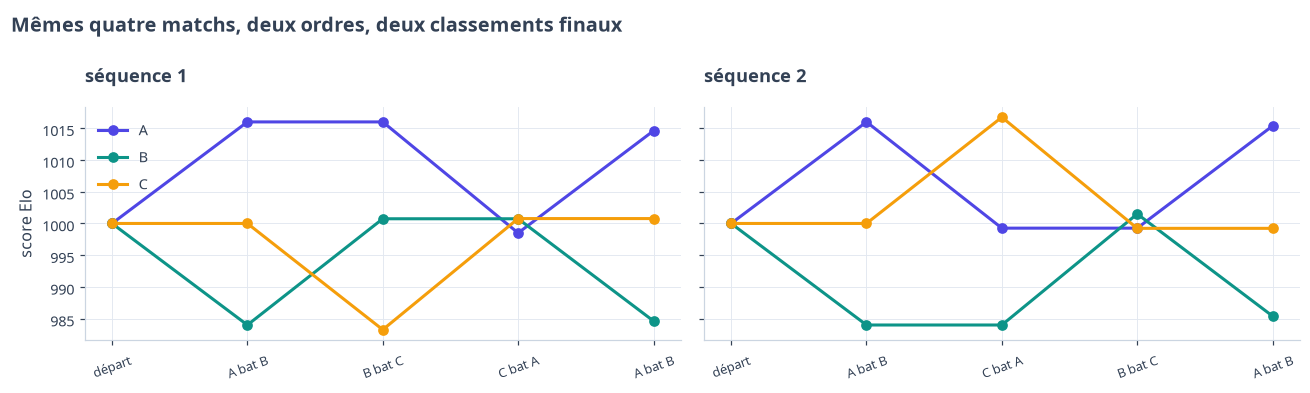

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, s, t in [(axes[0], s1, "séquence 1"), (axes[1], s2, "séquence 2")]:
    for m, c in zip("ABC", [INDIGO, TEAL, AMBER]):
        ax.plot(range(len(s) + 1), [1000] + list(s[m]), "o-", color=c, label=m)
    ax.set_xticks(range(len(s) + 1)); ax.set_xticklabels(["départ"] + list(s.match), rotation=20, fontsize=8.5)
    ax.set_title(t)
axes[0].set_ylabel("score Elo"); axes[0].legend()
finish(fig, "Mêmes quatre matchs, deux ordres, deux classements finaux")
plt.show()

> **À retenir.** Elo est un gradient stochastique à pas constant sur la log-vraisemblance
> logistique : il conserve la somme des scores, mais son résultat dépend de l'ordre des
> matchs.

## Exercice 3.12 : Table 3-6, chiffres de LMSYS et appariement adaptatif

**Énoncé.**

1. Classer les cinq modèles de la table 3-6 (a) par nombre total de victoires, (b) par
   Bradley-Terry, (c) par « nombre de duels gagnés » (règle de Copeland). Les trois
   classements coïncident-ils ? Pourquoi ?
2. LMSYS (janvier 2024) : 57 modèles, 244 000 comparaisons. Combien de comparaisons par
   paire ? Si l'on voulait pouvoir détecter un écart de 55/45 sur **chaque** paire,
   combien de comparaisons faudrait-il au total ?
3. Objectif plus modeste : identifier le **meilleur** modèle parmi 10, aux forces très
   dispersées. Comparer par simulation l'appariement uniforme et un appariement adaptatif
   qui concentre les matchs sur les candidats au titre.

**Rappels.** Bradley-Terry, transitivité, croissance quadratique du nombre de paires,
taille d'échantillon pour un taux de victoire (cours 4 sections 4, 5 et 7).

In [15]:
W = ev.book_win_matrix()
s_bt = ev.bradley_terry(W)
copeland = (W > W.T).sum(1)
R = pd.DataFrame({"victoires totales": W.sum(1), "Bradley-Terry (Elo)": ev.bt_to_elo(s_bt).round(0),
                  "duels gagnés (Copeland)": copeland}, index=[f"M{i}" for i in range(1, 6)])
R["rang victoires"] = R["victoires totales"].rank(ascending=False, method="min").astype(int)
R["rang BT"] = R["Bradley-Terry (Elo)"].rank(ascending=False, method="min").astype(int)
R["rang Copeland"] = R["duels gagnés (Copeland)"].rank(ascending=False, method="min").astype(int)
R

,victoires totales,Bradley-Terry (Elo),duels gagnés (Copeland),rang victoires,rang BT,rang Copeland
M1,1550.0,934.0,1,4,4,4
M2,2300.0,1043.0,3,2,2,1
M3,1800.0,970.0,2,3,3,3
M4,1550.0,934.0,1,4,4,4
M5,2800.0,1120.0,3,1,1,1


**Solution.**

*1.* Quand chaque paire a le même nombre de matchs, l'estimateur de Bradley-Terry
vérifie « victoires observées = victoires attendues » : son classement coïncide avec
celui des victoires totales (propriété du maximum de vraisemblance dans ce plan
équilibré). Copeland, qui compte les duels gagnés sans tenir compte des marges, peut
différer : il ignore qu'un 90/10 pèse plus qu'un 60/40. En présence de cycles, chaque
règle « résout » l'intransitivité à sa façon, et il n'existe pas de classement correct
unique : on ne peut que juger lequel **prédit** le mieux.

*2.* $\binom{57}{2} = 1\,596$ paires, $244\,000/1\,596 \approx 153$ comparaisons par paire.
Pour un écart 55/45, il faut environ 783 matchs par paire, soit
$1\,596\times783 \approx 1{,}25$ million de comparaisons, cinq fois le volume de LMSYS ;
pour 51/49, ce serait plus de 31 millions. D'où l'importance de la transitivité (ne pas
tout comparer) et d'un appariement intelligent. $\blacksquare$

In [16]:
n_pairs = 57 * 56 // 2
print(f"{n_pairs} paires ; {244_000 / n_pairs:.0f} comparaisons par paire ; "
      f"55/45 sur chaque paire : {n_pairs * ev.matches_needed(0.55):,} comparaisons ; "
      f"51/49 : {n_pairs * ev.matches_needed(0.51):,}".replace(",", " "))

1596 paires ; 153 comparaisons par paire ; 55/45 sur chaque paire : 1 249 668 comparaisons ; 51/49 : 31 313 520


*3. Simulation.* 10 modèles aux forces espacées de 60 points Elo en moyenne (avec un peu
de bruit). Stratégie uniforme : paires tirées au hasard. Stratégie adaptative : par lots
de 50 matchs, on réestime Bradley-Terry et l'on ne fait jouer que des paires parmi les
**trois premiers** du classement courant. On mesure la probabilité d'identifier le vrai
meilleur modèle.

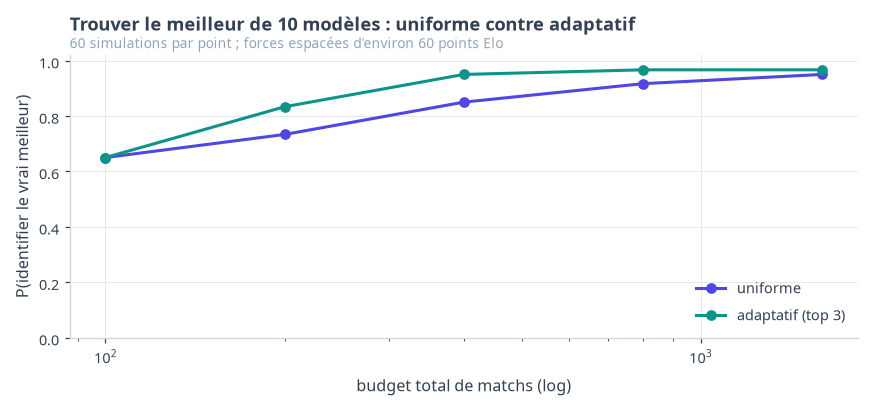

,uniforme,adaptatif (top 3)
100,0.6500,0.6500
200,0.7333,0.8333
400,0.8500,0.9500
800,0.9167,0.9667
1600,0.9500,0.9667


In [17]:
def identifie_meilleur(budget, adaptatif, reps=60, n_models=10, lot=50):
    succes = 0
    for r in range(reps):
        g = np.random.default_rng(500 + r)
        vraie = np.sort(g.normal(0, 15, n_models) + 60 * np.arange(n_models))[::-1]
        Pm = ev.prob_matrix_from_elo(vraie)
        hist = []
        s = np.zeros(n_models)
        while len(hist) < budget:
            if adaptatif and len(hist) >= 100:
                top = np.argsort(-s)[:3]
                paires = list(combinations(top, 2))
            else:
                paires = list(combinations(range(n_models), 2))
            for k in g.integers(len(paires), size=lot):
                a, b = paires[k]
                hist.append((int(a), int(b), float(g.random() < Pm[a, b])))
            s = ev.bradley_terry(ev.win_matrix(hist, n_models), prior=1.0, n_iter=200)
        succes += int(np.argmax(s) == 0)
    return succes / reps


budgets = [100, 200, 400, 800, 1600]
res = pd.DataFrame({"uniforme": [identifie_meilleur(b, False) for b in budgets],
                    "adaptatif (top 3)": [identifie_meilleur(b, True) for b in budgets]}, index=budgets)
fig, ax = plt.subplots(figsize=(8, 3.8))
for col, c in zip(res.columns, [INDIGO, TEAL]):
    ax.plot(res.index, res[col], "o-", color=c, label=col)
ax.set_xscale("log"); ax.set_ylim(0, 1.02)
ax.set_xlabel("budget total de matchs (log)"); ax.set_ylabel("P(identifier le vrai meilleur)")
ax.set_title("Trouver le meilleur de 10 modèles : uniforme contre adaptatif")
subtitle(ax, "60 simulations par point ; forces espacées d'environ 60 points Elo")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
res

Quand l'objectif est ciblé (trouver le meilleur) et les forces dispersées, concentrer les
matchs sur les prétendants est nettement plus efficace : le tirage uniforme gaspille
l'essentiel du budget sur des duels sans enjeu (le 7e contre le 9e). C'est la logique
des algorithmes de « bandits » pour l'identification du meilleur bras, et de la
recommandation du livre d'échantillonner les matchs qui réduisent le plus l'incertitude
utile. Le revers : le classement des modèles du bas reste imprécis.

> **À retenir.** Le coût du comparatif explose avec le nombre de modèles et la finesse
> des écarts à détecter. On le maîtrise en exploitant la transitivité et en choisissant
> les matchs selon l'objectif (meilleur modèle, classement complet, paire précise).

In [18]:
llm.free_gpu()